# Goma Salary Prediction with pythorch (DL)

##  Analyse :
ce notebook introuduit et fais une analyse simple sur les données des **salaires** de la **RDC**
et avec comme but de connaitre,analyser,nettoyer et comprendre nos variables 

### 1.import des libs

In [39]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

%matplotlib inline

### 2.load data (chargement des données)

In [40]:
chemin = Path('data/salary.csv')

try :
    if not chemin.exists():
        raise FileNotFoundError
    df = pd.read_csv(chemin)
    print('Données chargées avec succès')
except FileNotFoundError:
    print(f"le fichgier {chemin.name} n'existe pas dans le repertoire {chemin.parent}")

Données chargées avec succès


### 3.analyse simple des variables

In [41]:
# vue sur les premieres données

df.head()

,Unnamed: 0,age,experience,education,secteur,ville,salaire
0,0,50,29,1,2,2,125459.536774
1,1,36,15,0,1,1,73903.289698
2,2,29,5,3,0,2,74365.294677
3,3,42,18,0,1,2,95009.729834
4,4,40,16,0,0,0,50484.685510


In [42]:
# stats basiques
df.describe()

,Unnamed: 0,age,experience,education,secteur,ville,salaire
count,500.000000,500.000000,500.000000,500.00000,500.000000,500.000000,500.000000
mean,249.500000,41.322000,19.350000,1.42400,1.496000,0.954000,87518.317342
std,144.481833,11.051633,11.122541,1.10393,1.120936,0.805719,22330.804598
min,0.000000,22.000000,0.000000,0.00000,0.000000,0.000000,31570.264838
25%,124.750000,32.000000,10.000000,0.00000,0.750000,0.000000,72817.629152
50%,249.500000,43.000000,21.000000,1.00000,1.000000,1.000000,88882.902695
75%,374.250000,51.000000,29.000000,2.00000,3.000000,2.000000,103368.723924
max,499.000000,59.000000,39.000000,3.00000,3.000000,2.000000,148798.956226


In [43]:
# columns information : 
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  500 non-null    int64  
 1   age         500 non-null    int64  
 2   experience  500 non-null    int64  
 3   education   500 non-null    int64  
 4   secteur     500 non-null    int64  
 5   ville       500 non-null    int64  
 6   salaire     500 non-null    float64
dtypes: float64(1), int64(6)
memory usage: 27.5 KB


In [44]:
# globales metrics

print(f"Metriques essentiels : ")
print(f"{df.shape[0]} lignes")
print(f"{df.shape[1]} dont {df.columns}")
print(f"{df.isnull().sum().sum()} valeures vides")
print(f"{df.duplicated().sum()} Doublons detectés")

Metriques essentiels : 
500 lignes
7 dont Index(['Unnamed: 0', 'age', 'experience', 'education', 'secteur', 'ville',
       'salaire'],
      dtype='str')
0 valeures vides
0 Doublons detectés


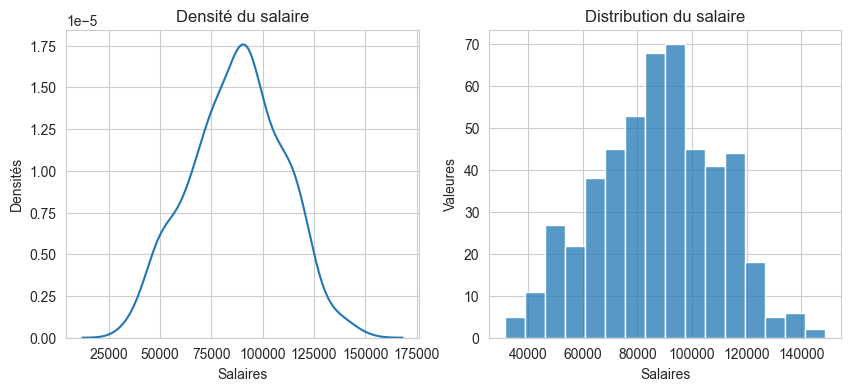

In [45]:
# distibution du salaire
sns.set_style('whitegrid')

plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
sns.kdeplot(x = 'salaire',data=df)
plt.title('Densité du salaire')
plt.xlabel('Salaires')
plt.ylabel('Densités')

plt.subplot(1,2,2)
sns.histplot(x='salaire',data = df)
plt.xlabel('Salaires')
plt.ylabel('Valeures')
plt.title('Distribution du salaire')
plt.show()

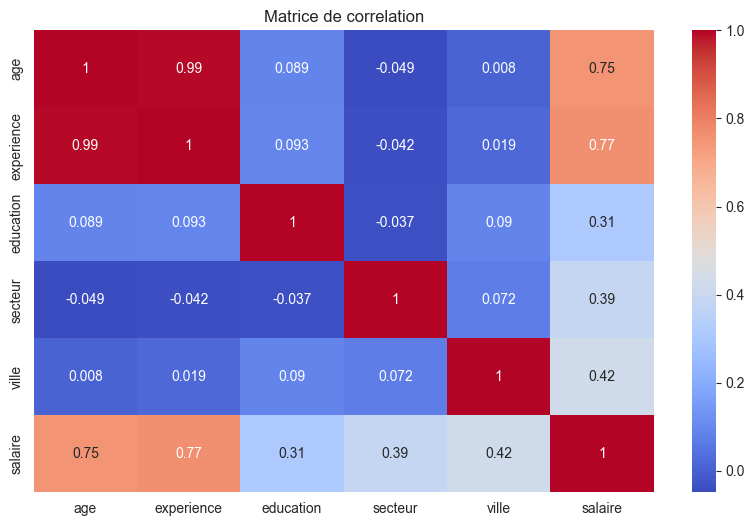

In [46]:
# correlation des variables

df_corr = df.drop('Unnamed: 0',axis=1).corr()
plt.figure(figsize=(10,6))
sns.heatmap(df_corr,annot=True,cmap='coolwarm')
plt.title('Matrice de correlation')
plt.show()

In [47]:
df_clean = df.drop('Unnamed: 0',axis=1)
target_corr = df_clean.corr()['salaire'].drop('salaire').sort_values(ascending=False)

print(f"Variables importantes : ")
print(target_corr)

Variables importantes : 
experience    0.765479
age           0.752146
ville         0.423757
secteur       0.387121
education     0.310195
Name: salaire, dtype: float64


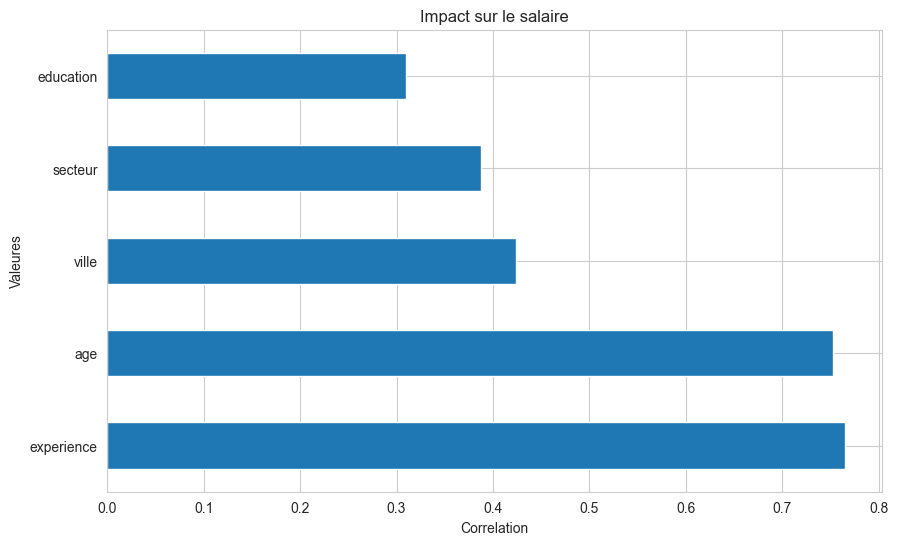

In [48]:
# visualisation for top_values

plt.figure(figsize=(10,6))
target_corr.plot(kind='barh')
plt.title('Impact sur le salaire')
plt.xlabel('Correlation')
plt.ylabel('Valeures')
plt.show()

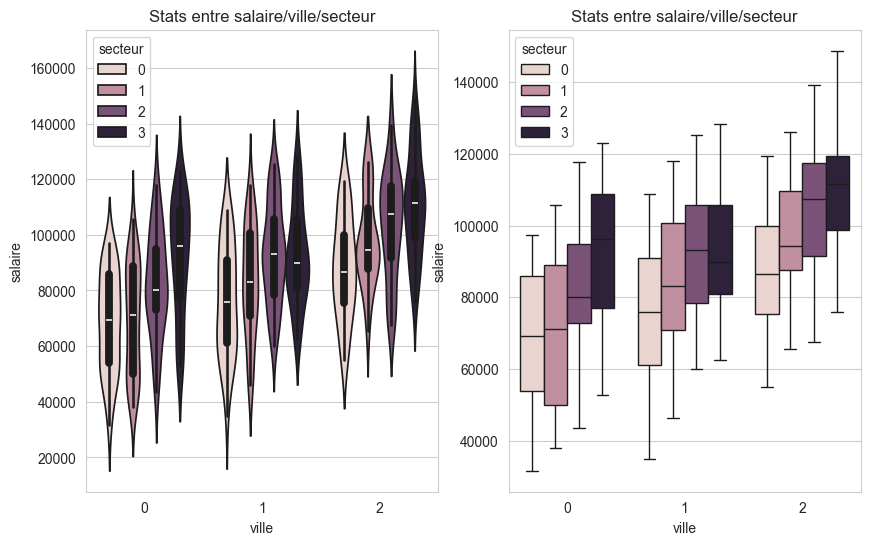

In [49]:
# statistiques salires par rapport à l'age et au type de ville

plt.figure(figsize=(10,6))
plt.subplot(1,2,1)
sns.violinplot(x='ville',y='salaire',data=df,hue='secteur')
plt.title('Stats entre salaire/ville/secteur')
plt.subplot(1,2,2)
sns.boxplot(x='ville',y='salaire',data=df,hue='secteur')
plt.title('Stats entre salaire/ville/secteur')
plt.show()

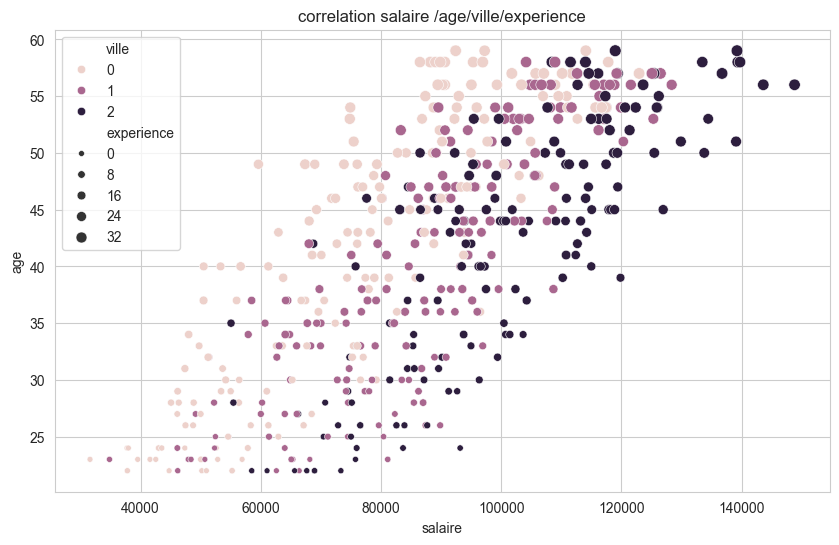

In [50]:
# pronfonde visualisation entre age/salaire/experience/Ville

plt.figure(figsize=(10,6))
sns.scatterplot(x='salaire',y='age',hue='ville',data=df,size='experience')
plt.title('correlation salaire /age/ville/experience')
plt.show()

### 4.save clean data 

In [52]:
df_clean.to_csv('data/salary_cleaned.csv')